# Predicción de eventos sísmicos de alta energía en una mina subterránea de carbón

**Objetivo.** Predecir, a partir de las mediciones sísmicas y sismoacústicas de un turno de 8 horas, si en el turno siguiente se registrará un golpe sísmico de energía mayor a 10⁴ J. El dataset define esa situación como estado peligroso (`class = 1`).

**Datos.** Dataset *seismic-bumps* del repositorio UCI Machine Learning Repository (Sikora y Wróbel). Cada fila resume un turno: 2584 registros con mediciones del geófono (`genergy`, `gpuls`...), conteo de golpes sísmicos por rango de energía (`nbumps`...) y evaluaciones de peligro hechas con métodos de la mina (`seismic`, `seismoacoustic`, `ghazard`).

**Desafío principal.** Solo 170 turnos (≈ 6,6%) tienen un evento en el turno siguiente, así que la clase positiva es muy rara y la exactitud (*accuracy*) no sirve como métrica.

**Qué se hace en este notebook.** Validación de los datos, selección de variables, creación de variables nuevas, comparación de modelos con validación cruzada, elección del umbral de decisión y una evaluación final única en el test.

In [1]:
import pandas as pd
import os
import numpy as np
from scipy.io import arff
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
directorio_datos = "data"
junta_directorio = os.path.join(directorio_datos, "seismic-bumps.arff")
data, meta = arff.loadarff(junta_directorio)
df = pd.DataFrame(data)

for col in df.select_dtypes(include="object"):
    df[col] = df[col].str.decode("utf-8")

Primero debemos saber como está estructurado el dataset, para eso hacemos un .info para ver si existen valores nulos

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2584 entries, 0 to 2583
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   seismic         2584 non-null   object 
 1   seismoacoustic  2584 non-null   object 
 2   shift           2584 non-null   object 
 3   genergy         2584 non-null   float64
 4   gpuls           2584 non-null   float64
 5   gdenergy        2584 non-null   float64
 6   gdpuls          2584 non-null   float64
 7   ghazard         2584 non-null   object 
 8   nbumps          2584 non-null   float64
 9   nbumps2         2584 non-null   float64
 10  nbumps3         2584 non-null   float64
 11  nbumps4         2584 non-null   float64
 12  nbumps5         2584 non-null   float64
 13  nbumps6         2584 non-null   float64
 14  nbumps7         2584 non-null   float64
 15  nbumps89        2584 non-null   float64
 16  energy          2584 non-null   float64
 17  maxenergy       2584 non-null   f

Como podemos observar, no existen valores nulos, ahora tambien necesito saber como estan estructurado los datos a grandes rasgos, para esto, nos ayudamos del .head() para ver algunas columnas y tambien un describe().T para ver que tipo de datos nos enfrentamos y aparte si hay valores raros o atipicos

In [4]:
df.head()

,seismic,seismoacoustic,shift,genergy,gpuls,gdenergy,gdpuls,ghazard,nbumps,nbumps2,nbumps3,nbumps4,nbumps5,nbumps6,nbumps7,nbumps89,energy,maxenergy,class
0,a,a,N,15180.0,48.0,-72.0,-72.0,a,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1,a,a,N,14720.0,33.0,-70.0,-79.0,a,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2000.0,2000.0,0
2,a,a,N,8050.0,30.0,-81.0,-78.0,a,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
3,a,a,N,28820.0,171.0,-23.0,40.0,a,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,3000.0,3000.0,0
4,a,a,N,12640.0,57.0,-63.0,-52.0,a,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
genergy,2584.0,90242.523220,229200.508894,100.0,11660.0,25485.0,52832.50,2595650.0
gpuls,2584.0,538.579334,562.652536,2.0,190.0,379.0,669.00,4518.0
gdenergy,2584.0,12.375774,80.319051,-96.0,-37.0,-6.0,38.00,1245.0
gdpuls,2584.0,4.508901,63.166556,-96.0,-36.0,-6.0,30.25,838.0
nbumps,2584.0,0.859520,1.364616,0.0,0.0,0.0,1.00,9.0
nbumps2,2584.0,0.393576,0.783772,0.0,0.0,0.0,1.00,8.0
nbumps3,2584.0,0.392802,0.769710,0.0,0.0,0.0,1.00,7.0
nbumps4,2584.0,0.067724,0.279059,0.0,0.0,0.0,0.00,3.0
nbumps5,2584.0,0.004644,0.068001,0.0,0.0,0.0,0.00,1.0
nbumps6,2584.0,0.000000,0.000000,0.0,0.0,0.0,0.00,0.0


Las columnas nbumps6, nbumps7 y nbumps89 valen 0 en todos los registros. Según la documentación, cuentan golpes en rangos de energía muy altos, que no ocurrieron en ningún turno registrado.

Podemos tambien ver si existen duplicados a .duplicated()

In [6]:
print(df.duplicated().sum())
df[df.duplicated(keep=False)]

6


,seismic,seismoacoustic,shift,genergy,gpuls,gdenergy,gdpuls,ghazard,nbumps,nbumps2,nbumps3,nbumps4,nbumps5,nbumps6,nbumps7,nbumps89,energy,maxenergy,class
87,a,a,N,63550.0,325.0,15.0,35.0,a,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
88,a,a,W,194580.0,697.0,-35.0,-32.0,a,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
89,a,a,N,63550.0,325.0,15.0,35.0,a,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
90,a,a,W,194580.0,697.0,-35.0,-32.0,a,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
970,a,b,N,5250.0,66.0,-49.0,36.0,a,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
971,a,b,N,19420.0,60.0,98.0,20.0,a,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
972,a,b,N,5250.0,66.0,-49.0,36.0,a,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
973,a,b,N,19420.0,60.0,98.0,20.0,a,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1015,a,a,N,590.0,11.0,-74.0,-72.0,a,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1016,a,a,N,3720.0,43.0,75.0,8.0,a,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


Dado que no tenemos como corroborar de que realmente sean duplicados ya que no tenemos una columna de tiempo o algo que realmente los pueda diferenciar, como instancias de tiempo o algun id de evento, hora, etc seria muy coincidente de que los sensores tomen exactamente la misma cantidad de todo en 2 turnos distintos como energia, cantidad de pulsaciones. En resumen, no es posible confirmar que sean errores, y son pocas filas (6 de 2584), por lo que se conservan.

Tambien podemos revisar los valores unicos que contienen cada columna. Como antes mencionamos el nbumps6-7-89 tenian un solo valor segun el .describe()

In [7]:
df.nunique().sort_values()

nbumps89             1
nbumps6              1
nbumps7              1
seismic              2
nbumps5              2
shift                2
class                2
seismoacoustic       3
ghazard              3
nbumps4              4
nbumps3              7
nbumps2              7
nbumps              10
maxenergy           33
energy             242
gdpuls             292
gdenergy           334
gpuls             1128
genergy           2212
dtype: int64

como sospechabamos las primeras 3 columnas que se muestran son solamente 0, por lo que se descartarian directamente para cualquier tipo de analisis o estudio

Se verifica tambien con el .describe que los valores sean logicamente correctos, que las energias sean positivas, que el conteo de pulsos no sea negativo, etc.

ahora vemos que sucede con las clases que tenemos a disposicion, para ver si existe un desbalanceo de ellas

In [8]:
df['class'].value_counts()

class
0    2414
1     170
Name: count, dtype: int64

Vemos que existe un desbalance enorme entre las clases diciendonos directamente que es una mina subterranea con pocos eventos que superan los 10⁴[J], en donde, solo 170 de 2584 turnos (6,6%) tienen un evento de alta energía en el turno siguiente. Con una clase tan rara, la exactitud (accuracy) no sirve como métrica, y por eso se usarán PR-AUC, recall y precisión.

In [9]:
df['class'].value_counts(normalize=True)

class
0    0.934211
1    0.065789
Name: proportion, dtype: float64

Ahora necesitamos saber que variables vamos a tomar en consideracion para ir entregandole a nuestro/s modelos de aprendizaje, como nuestra idea es predecir eventos sismologicos con el fin de precaver accidentes dentro de la mina subterranea de carbon en este caso.

Se parte de casi todas las columnas del dataset como candidatas. Solo se excluyen `class`, porque es la variable objetivo (lo que se quiere predecir), y `nbumps6`, `nbumps7` y `nbumps89`, porque valen 0 en todos los registros y no aportan información. A continuación se evalúa cuáles de las columnas restantes tienen relación con el evento peligroso.

### Codificación de variables categóricas

Cuatro columnas del dataset son texto: `seismic`, `seismoacoustic`, `ghazard` y `shift`. Los
modelos solo trabajan con números, así que se convierten con `OrdinalEncoder`, que asigna un
entero a cada categoría según su orden alfabético.

- **`seismic`, `seismoacoustic` y `ghazard`** son evaluaciones del nivel de peligro, con
  categorías de la `a` a la `d`. Su orden alfabético coincide con el orden de peligro (de menor
  a mayor), por lo que un número más alto significa más peligro.
- **`shift`** indica el tipo de turno y solo tiene dos valores, sin un orden natural. Se codifica
  igual, porque con árboles de decisión y sus variantes (random forest, gradient boosting) el
  orden asignado a una variable de dos categorías no afecta el resultado.

El encoder se ajusta sobre todo el dataset antes del split. Esto no genera fuga de información,
ya que las categorías son fijas y conocidas de antemano (no se aprende nada de las
distribuciones de los datos).

In [10]:
from sklearn.preprocessing import OrdinalEncoder

variables_categoricas = ["seismic", "seismoacoustic", "ghazard", "shift"]

enc = OrdinalEncoder()

df[variables_categoricas] = enc.fit_transform(df[variables_categoricas])

df.head()

,seismic,seismoacoustic,shift,genergy,gpuls,gdenergy,gdpuls,ghazard,nbumps,nbumps2,nbumps3,nbumps4,nbumps5,nbumps6,nbumps7,nbumps89,energy,maxenergy,class
0,0.0,0.0,0.0,15180.0,48.0,-72.0,-72.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,14720.0,33.0,-70.0,-79.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2000.0,2000.0,0
2,0.0,0.0,0.0,8050.0,30.0,-81.0,-78.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
3,0.0,0.0,0.0,28820.0,171.0,-23.0,40.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,3000.0,3000.0,0
4,0.0,0.0,0.0,12640.0,57.0,-63.0,-52.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


In [11]:
for col, cats in zip(variables_categoricas, enc.categories_):
    print(col, "->", list(cats))

seismic -> ['a', 'b']
seismoacoustic -> ['a', 'b', 'c']
ghazard -> ['a', 'b', 'c']
shift -> ['N', 'W']


En este caso shift tambien lo consideramos como OrdinalEncoder ya que para los modelos que se quieren utilizar da lo mismo esta ref de valores que tiene (binaria) en donde el orden da lo mismo.

Ahora para ver si las variables que estamos considerando, que son todas excelto class y los nbumps6-7-89 son todos validos, vemos si es consistente con nuestro objetivo, para esto primero debemos hacer el split entre los datos de test y train definiendo que particionaremos el dataset con un 25% de los turnos como test y tambien usando el stratify = y (variable objetivo) para mantener la proporcion de los eventos

In [12]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["class"] + ["nbumps6", "nbumps7", "nbumps89"])
y = df["class"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

In [13]:
X_train.nunique().sort_values()
(X_train == 0).mean().sort_values(ascending=False)

nbumps5           0.994840
nbumps4           0.935501
ghazard           0.909185
nbumps2           0.728070
nbumps3           0.719814
seismic           0.647575
seismoacoustic    0.610423
energy            0.557792
nbumps            0.557792
maxenergy         0.557792
shift             0.355005
gdpuls            0.014448
gdenergy          0.008772
genergy           0.000000
gpuls             0.000000
dtype: float64

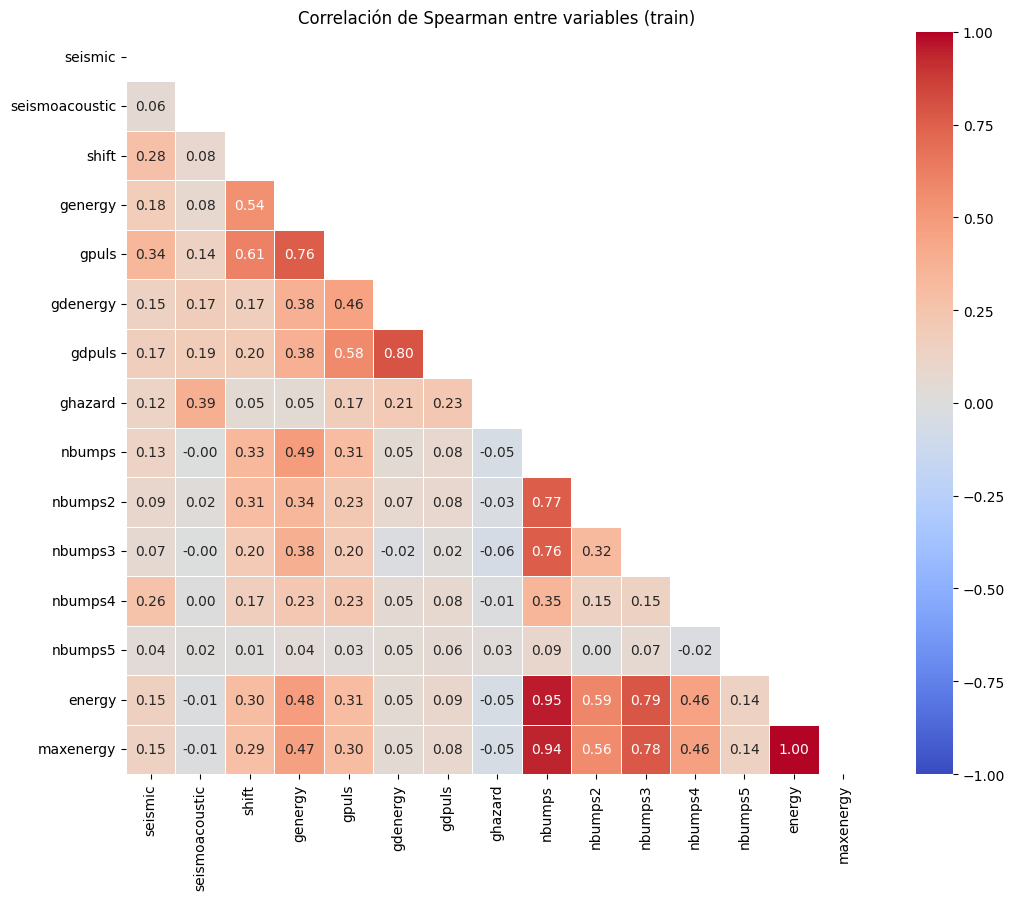

In [14]:
corr = X_train.corr(method="spearman")
mascara = np.triu(np.ones_like(corr, dtype=bool))   # oculta la mitad repetida

plt.figure(figsize=(11, 9))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0,
            linewidths=0.5, square=True)
plt.title("Correlación de Spearman entre variables (train)")
plt.tight_layout()
plt.show()

In [15]:
from sklearn.metrics import roc_auc_score

res = {c: roc_auc_score(y_train, X_train[c]) for c in X_train.columns}
print(pd.Series(res).sub(0.5).abs().add(0.5).sort_values(ascending=False))

nbumps            0.743687
energy            0.715055
genergy           0.707228
maxenergy         0.706846
nbumps2           0.693286
gpuls             0.686568
nbumps3           0.677031
shift             0.623135
seismic           0.579006
gdpuls            0.539967
nbumps4           0.524191
gdenergy          0.519646
ghazard           0.511404
nbumps5           0.501420
seismoacoustic    0.500475
dtype: float64


In [16]:
from sklearn.feature_selection import mutual_info_classif
mi = mutual_info_classif(X_train, y_train, random_state=42)
pd.Series(mi, index=X_train.columns).sort_values(ascending=False)

nbumps            0.021540
nbumps2           0.020551
energy            0.019566
maxenergy         0.015579
nbumps4           0.013525
nbumps3           0.010938
gpuls             0.010771
genergy           0.010075
shift             0.009230
seismic           0.003904
seismoacoustic    0.002328
gdpuls            0.000464
gdenergy          0.000000
ghazard           0.000000
nbumps5           0.000000
dtype: float64

### Evaluación de las columnas candidatas

Antes de modelar, se revisó si las columnas candidatas realmente se relacionan con el evento
peligroso. Todo el análisis se hizo solo con el conjunto de entrenamiento, para que el test no
influya en ninguna decisión.

**Relación con el objetivo.** Se aplicaron dos pruebas, columna por columna, contra `class`:

- **AUC univariado:** mide qué tan bien separa los turnos con evento de los que no una columna
  por sí sola. Un valor de 0,5 equivale a lanzar una moneda (sin información). La tabla muestra
  |AUC − 0,5| + 0,5, por lo que indica la fuerza de la relación pero no su sentido.
- **Información mutua:** mide cuánto reduce la incertidumbre sobre `class` conocer el valor de
  la columna, incluyendo relaciones no lineales.

Ambas pruebas coincidieron en señalar dos bloques con señal:

- **Bloque de golpes sísmicos:** `nbumps`, `nbumps2`, `energy` y `maxenergy` (AUC entre 0,69 y
  0,74).
- **Bloque del geófono:** `genergy` y `gpuls` (AUC de 0,71 y 0,69).

Las columnas `ghazard`, `seismoacoustic`, `gdenergy`, `gdpuls` y `nbumps5` quedaron cerca de
0,5 en AUC y cerca de 0 en información mutua, es decir, no muestran relación con el evento por
sí solas.

Ninguna columna supera un AUC de 0,75 y la información mutua máxima es baja, lo que anticipa
que ninguna variable individual basta para predecir el evento.

**Redundancia.** La correlación de Spearman entre `energy` y `maxenergy` es de 1: llevan
casi la misma información, y solo difieren en turnos con dos o más golpes. También hay
correlación alta dentro del bloque de golpes (`nbumps`, `nbumps2`, `nbumps3`, `energy`), porque
`nbumps` son los conteos por rango de energía.

**Limitación.** Estas pruebas miran una columna a la vez y no detectan interacciones entre
variables, por lo que sirven como orientación y no como decisión definitiva.

### Selección de variables

Con base en lo anterior, se conservan 5 variables: `nbumps`, `energy`, `genergy`, `nbumps2` y
`gpuls`. De `energy` y `maxenergy` se mantiene `energy`, que obtuvo un AUC y una información
mutua algo mayores y suma la energía de todos los golpes del turno.

Las evaluaciones de peligro (`seismic`, `seismoacoustic`, `ghazard`) y las columnas de
desviación (`gdenergy`, `gdpuls`) no mostraron señal propia suficiente y se descartan en esta
etapa. Quedan fuera [`shift`, `nbumps3` y `nbumps4`, que mostraron señal débil o moderada en
alguna de las pruebas, para trabajar con un conjunto reducido y fácil de explicar].

Es una selección provisional: se confirmará con los resultados del modelo, y la comparación
entre modelos con distintos conjuntos de columnas queda como mejora posible.

### Ingeniería de características

Consiste en crear variables nuevas a partir de las existentes, para facilitarle al modelo
patrones que no ve directamente. A partir de las 5 variables seleccionadas se crean dos:

- `energia_por_pulso` = `genergy / (gpuls + 1)`: distingue muchas fracturas pequeñas de pocas
  fracturas grandes.
- `genergy_vs_energy` = `genergy / (energy + 1)`: relaciona la energía registrada por el
  geófono con la de los golpes sísmicos del turno.

Ambas se calculan fila a fila, usando solo los valores de ese mismo turno, por lo que no hay
fuga de información. Se evaluará si mejoran el rendimiento frente a las 5 variables base.

Al hacer el split, `X_train` y `X_test` conservaron las 15 columnas originales, porque en ese
momento se estaba evaluando cuáles eran más relevantes. Tras ese análisis se seleccionaron 5:
`nbumps`, `energy`, `genergy`, `nbumps2` y `gpuls`.

Ahora se crean copias de `X_train` y `X_test` que contienen solo esas 5 columnas. Sobre ellas se
agregarán las variables nuevas (ratios y combinaciones calculadas a partir de estas mismas
columnas). El split no se repite: las filas de train y test son las mismas, solo se reducen las
columnas.

Los conjuntos originales con las 15 columnas se mantienen intactos, para poder comparar el
rendimiento antes y después de crear las variables nuevas.

In [17]:
base = ["nbumps", "energy", "genergy", "nbumps2", "gpuls"]

X_train_fe = X_train[base].copy()
X_test_fe  = X_test[base].copy()

for d in (X_train_fe, X_test_fe):
    d["energia_por_pulso"] = d["genergy"] / (d["gpuls"] + 1)
    d["genergy_vs_energy"] = d["genergy"] / (d["energy"] + 1)

print(X_train_fe.columns.tolist())
print(X_test_fe.columns.tolist()) 

['nbumps', 'energy', 'genergy', 'nbumps2', 'gpuls', 'energia_por_pulso', 'genergy_vs_energy']
['nbumps', 'energy', 'genergy', 'nbumps2', 'gpuls', 'energia_por_pulso', 'genergy_vs_energy']


### Evaluación con validación cruzada

Ahora se mide cuánto aportan las variables seleccionadas y las creadas. Todo se evalúa con validación cruzada sobre el conjunto de entrenamiento, sin tocar el test.

**Cómo funciona.** El conjunto de entrenamiento se divide en 5 partes (*folds*, manteniendo la proporción de eventos en cada una). En cada vuelta se entrena el modelo con 4 partes y se evalúa con la restante, que no vio durante ese entrenamiento. El proceso se repite 5 veces con cortes distintos, lo que da 25 evaluaciones por métrica. Se reporta su promedio y su desviación estándar: con tan pocos eventos, el resultado varía bastante entre cortes, y esa
desviación indica cuánto ruido hay.

**Qué se compara.** Se entrena el mismo modelo con dos conjuntos de columnas:

- **Base:** las 5 variables seleccionadas.
- **Con nuevas:** las 5 variables más las 2 creadas (`energia_por_pulso` y `genergy_vs_energy`).

Se usa el mismo modelo, los mismos parámetros y los mismos cortes en ambos casos, de modo que cualquier diferencia se deba a las variables y no a otra cosa. Una mejora solo se considera real si supera la desviación estándar.

**Métricas.** Como solo alrededor de un 6,6% de los turnos tiene un evento, la exactitud (*accuracy*) no es informativa: un modelo que siempre dijera "sin evento" acertaría más del 93% y sería inútil. Se usan en su lugar:

- **PR-AUC** (métrica principal): qué tan bien se ordenan los turnos de mayor a menor riesgo, fijándose en la calidad de las alarmas. Un modelo sin información obtiene un valor igual a la proporción de eventos (≈ 0,066).
- **ROC-AUC:** capacidad general de separar turnos con evento de turnos sin evento (0,5 = azar).
- **Recall:** de los eventos reales, cuántos avisa el modelo.
- **Precisión:** de las alarmas que da, cuántas son reales.
- **F1** y **balanced accuracy:** resúmenes que combinan las anteriores.

Recall, precisión, F1 y balanced accuracy dependen del umbral de decisión (aquí, el que usa el modelo por defecto), mientras que PR-AUC y ROC-AUC no.

El modelo principal es un random forest con `class_weight="balanced"`, para compensar el desbalance entre clases. Más adelante se compara con gradient boosting.

In [18]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)

rf = RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=10,
                            class_weight="balanced", random_state=42, n_jobs=-1)

metricas = ["average_precision", "roc_auc", "recall", "precision", "f1", "balanced_accuracy"]

r_base = cross_validate(rf, X_train[base], y_train, cv=cv, scoring=metricas)

for m in metricas:
    b = r_base[f"test_{m}"]
    print(f"{m:18s} base: {b.mean():.3f} ± {b.std():.3f}")

average_precision  base: 0.225 ± 0.049
roc_auc            base: 0.747 ± 0.056
recall             base: 0.530 ± 0.116
precision          base: 0.182 ± 0.034
f1                 base: 0.270 ± 0.051
balanced_accuracy  base: 0.681 ± 0.056


In [19]:
r_fe   = cross_validate(rf, X_train_fe, y_train, cv=cv, scoring=metricas)

for m in metricas:
    f =r_fe[f"test_{m}"]
    print(f"{m:18s}con nuevas: {f.mean():.3f} ± {f.std():.3f}")

average_precision con nuevas: 0.229 ± 0.060
roc_auc           con nuevas: 0.749 ± 0.050
recall            con nuevas: 0.513 ± 0.122
precision         con nuevas: 0.183 ± 0.038
f1                con nuevas: 0.269 ± 0.057
balanced_accuracy con nuevas: 0.676 ± 0.060


In [20]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_validate

metricas = ["average_precision", "roc_auc", "recall", "precision", "f1", "balanced_accuracy"]

gb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_depth=3,
                                    min_samples_leaf=20, class_weight="balanced",
                                    random_state=42)

r_gb = cross_validate(gb, X_train[base], y_train, cv=cv, scoring=metricas)

for m in metricas:
    g = r_gb[f"test_{m}"]
    print(f"{m:18s} gradient boosting: {g.mean():.3f} ± {g.std():.3f}")

average_precision  gradient boosting: 0.204 ± 0.051
roc_auc            gradient boosting: 0.719 ± 0.048
recall             gradient boosting: 0.510 ± 0.110
precision          gradient boosting: 0.165 ± 0.030
f1                 gradient boosting: 0.249 ± 0.046
balanced_accuracy  gradient boosting: 0.664 ± 0.054


In [21]:
fe_gb = cross_validate(gb, X_train_fe, y_train, cv=cv, scoring=metricas)

for m in metricas:
    g = fe_gb[f"test_{m}"]
    print(f"{m:18s} gradient boosting: {g.mean():.3f} ± {g.std():.3f}")

average_precision  gradient boosting: 0.201 ± 0.061
roc_auc            gradient boosting: 0.713 ± 0.046
recall             gradient boosting: 0.494 ± 0.109
precision          gradient boosting: 0.163 ± 0.030
f1                 gradient boosting: 0.245 ± 0.047
balanced_accuracy  gradient boosting: 0.658 ± 0.054


### Comparación con gradient boosting

Para ver si el resultado depende del algoritmo, se repite la evaluación con `HistGradientBoostingClassifier`, con parámetros conservadores (profundidad 3, tasa de aprendizaje baja, `class_weight="balanced"`). Se usan los mismos cortes de validación cruzada y las mismas métricas.

| Modelo | Columnas | PR-AUC | ROC-AUC |
|---|---|---|---|
| Random forest | base (5) | 0,225 ± 0,049 | 0,747 ± 0,056 |
| Random forest | + nuevas (7) | 0,229 ± 0,060 | 0,749 ± 0,050 |
| Gradient boosting | base (5) | 0,204 ± 0,051 | 0,719 ± 0,048 |
| Gradient boosting | + nuevas (7) | 0,201 ± 0,061 | 0,713 ± 0,046 |

**Resultado.** Con gradient boosting las variables nuevas tampoco mejoran el rendimiento (0,204 contra 0,201 en PR-AUC, average precision), igual que con random forest. Que dos algoritmos distintos den la misma conclusión refuerza que `energia_por_pulso` y `genergy_vs_energy` no aportan información que los modelos no extrajeran ya de las columnas originales.

Entre modelos, random forest queda levemente por encima, pero la diferencia (unos 0,02 en PR-AUC) es menor que la desviación estándar, por lo que no se puede afirmar que sea mejor. Se elige random forest como modelo final por rendir igual o algo más y por ser más estable con pocos eventos positivos.

Con base en estos resultados, el modelo final usa las 5 variables base, que es la versión más simple.

### Elección del umbral de decisión

El modelo entrega una probabilidad de evento para cada turno, y hay que decidir desde qué probabilidad se activa una alarma (el umbral). Un umbral bajo detecta más eventos pero genera más falsas alarmas, y uno alto hace lo contrario.

Se elige el umbral que maximiza el **F2**, una medida que combina precisión y recall dándole más peso al recall. Se justifica porque, en este contexto, un evento no avisado es más costoso que una falsa alarma: según la descripción del dataset, ante un aviso el personal de supervisión puede aplicar medidas preventivas o retirar trabajadores de la zona.

Para no usar el test, las probabilidades se obtienen con validación cruzada sobre el train
(cada turno se predice con un modelo que no lo vio durante su entrenamiento) y el umbral se
elige sobre ellas.

In [22]:
import numpy as np
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import precision_recall_curve

proba_cv = cross_val_predict(
    rf, X_train[base], y_train,
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    method="predict_proba",
)[:, 1]

prec, rec, umbrales = precision_recall_curve(y_train, proba_cv)
f2 = 5 * prec[:-1] * rec[:-1] / (4 * prec[:-1] + rec[:-1] + 1e-12)

i = np.argmax(f2)
umbral = umbrales[i]

print(f"Umbral elegido (máx. F2): {umbral:.3f}")
print(f"En train -> F2: {f2[i]:.3f} | recall: {rec[i]:.2f} | precisión: {prec[i]:.2f}")
print(f"Alarmas por cada 100 turnos: {(proba_cv >= umbral).mean() * 100:.1f}")

Umbral elegido (máx. F2): 0.563
En train -> F2: 0.412 | recall: 0.52 | precisión: 0.22
Alarmas por cada 100 turnos: 15.5


**Resultado.** El umbral elegido es 0,563. Sobre el train (con predicciones de validación cruzada) logra un recall de 0,52 y una precisión de 0,22, con alrededor de 15,5 alarmas por cada 100 turnos.

### Evaluación final en el test

Es la única evaluación sobre el conjunto de prueba, que no se usó para ninguna decisión anterior (ni para elegir variables, ni modelo, ni umbral). Se entrena el random forest con las 5 variables base sobre todo el train y se evalúa con el umbral elegido. Como referencia, se compara con el azar y con la regla más simple posible: usar solo `nbumps`.

In [23]:
from sklearn.metrics import (confusion_matrix, recall_score, precision_score,
                             fbeta_score, average_precision_score, roc_auc_score)

rf.fit(X_train[base], y_train)
proba_test = rf.predict_proba(X_test[base])[:, 1]
pred_test = (proba_test >= umbral).astype(int)

print("Matriz de confusión (filas = real, columnas = predicho):")
print(confusion_matrix(y_test, pred_test))
print(f"\nrecall:    {recall_score(y_test, pred_test):.3f}")
print(f"precisión: {precision_score(y_test, pred_test):.3f}")
print(f"F2:        {fbeta_score(y_test, pred_test, beta=2):.3f}")
print(f"PR-AUC:    {average_precision_score(y_test, proba_test):.3f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, proba_test):.3f}")

print("\n--- Referencias ---")
print(f"Azar (PR-AUC): {y_test.mean():.3f}")
print(f"nbumps sola -> PR-AUC: {average_precision_score(y_test, X_test['nbumps']):.3f}")

Matriz de confusión (filas = real, columnas = predicho):
[[545  59]
 [ 24  18]]

recall:    0.429
precisión: 0.234
F2:        0.367
PR-AUC:    0.276
ROC-AUC:   0.812

--- Referencias ---
Azar (PR-AUC): 0.065
nbumps sola -> PR-AUC: 0.172


**Resultados en el test** (646 turnos, 42 con evento):

| | Valor |
|---|---|
| PR-AUC | 0,276 (azar: 0,065) |
| ROC-AUC | 0,812 |
| Recall | 0,43 (18 de 42 eventos detectados) |
| Precisión | 0,23 |
| F2 | 0,37 |
| Falsas alarmas | 59 |
| Eventos no avisados | 24 |
| `nbumps` sola (PR-AUC) | 0,172 |

**Interpretación.**

- El modelo supera al azar (PR-AUC cuatro veces mayor). La comparación con la regla basada solo en `nbumps` (0,276 frente a 0,172) se analiza en la sección siguiente: la ventaja es modesta y menos clara de lo que sugiere esta cifra.
- Con el umbral elegido, el modelo avisa un poco menos de la mitad de los eventos, y de cada cuatro alarmas, una es real. Unos 12 de cada 100 turnos generan alarma.
- El PR-AUC y el ROC-AUC del test son algo mayores que los de la validación cruzada (0,225 y 0,747). No debe leerse como una mejora: con solo 42 eventos en el test, las diferencias de este tamaño son esperables por azar. Lo importante es que no hay señales de sobreajuste.
- El resultado se reporta tal cual, sin ajustes posteriores.

**Limitaciones.** Pocos eventos positivos (170 en todo el dataset), lo que vuelve ruidosas todas las métricas. Cada fila describe un solo turno, sin historia previa. Los datos provienen de una sola mina. El rendimiento no es suficiente para usar el modelo como herramienta única de alerta: deja pasar más de la mitad de los eventos y la mayoría de las alarmas son falsas.

## ¿Cuánto aporta el modelo frente a una regla simple?

En el análisis univariado, `nbumps` sola ya alcanzaba un AUC de 0,74 en el train, muy cerca del ROC-AUC del random forest en validación cruzada (0,747). Antes de concluir que el modelo aporta algo, hay que comprobarlo contra esa regla simple, y no solo en el test, donde hay únicamente 42 eventos.

Se hace en dos pasos, ambos sin tomar ninguna decisión nueva sobre el modelo:

1. **Validación cruzada en el train:** se evalúa `nbumps` sola (con una regresión logística de una variable) con los mismos cortes que el random forest.
2. **Bootstrap en el test:** se remuestrea el test para estimar cuánta incertidumbre tiene la diferencia observada.

Primero, la comparación en validación cruzada:

In [27]:
from sklearn.linear_model import LogisticRegression

lr_nb = LogisticRegression(class_weight="balanced")
r_nb = cross_validate(lr_nb, X_train[["nbumps"]], y_train, cv=cv, scoring=metricas)

for m in ["average_precision", "roc_auc"]:
    b, n = r_base[f"test_{m}"], r_nb[f"test_{m}"]
    print(f"{m:18s} random forest: {b.mean():.3f} ± {b.std():.3f} | solo nbumps: {n.mean():.3f} ± {n.std():.3f}")

average_precision  random forest: 0.225 ± 0.049 | solo nbumps: 0.185 ± 0.041
roc_auc            random forest: 0.747 ± 0.056 | solo nbumps: 0.744 ± 0.051


Como ambos modelos se evaluaron con exactamente los mismos cortes, la comparación es más justa fold a fold que comparando promedios. A continuación se calcula la diferencia de PR-AUC en cada corte y se aplica el *t-test remuestreado corregido* (Nadeau y Bengio, 2003), que ajusta por el hecho de que los cortes repetidos comparten datos y no son independientes.

In [28]:
dif = r_base["test_average_precision"] - r_nb["test_average_precision"]

# t-test remuestreado corregido (Nadeau y Bengio): los folds repetidos no son independientes
k = len(dif)
var_corr = (1 / k + 1 / 4) * dif.var(ddof=1)   # 1/4 = n_test / n_train en 5 folds
t = dif.mean() / np.sqrt(var_corr)

print(f"Diferencia media en PR-AUC (RF - nbumps): {dif.mean():.3f} ± {dif.std():.3f}")
print(f"Folds donde el RF gana: {(dif > 0).mean() * 100:.0f}%")
print(f"t corregido: {t:.2f}  (valores sobre ~2 sugieren diferencia real)")

Diferencia media en PR-AUC (RF - nbumps): 0.040 ± 0.052
Folds donde el RF gana: 80%
t corregido: 1.39  (valores sobre ~2 sugieren diferencia real)


Ahora, sobre el test: se remuestrea con reemplazo 2.000 veces y en cada remuestreo se calcula la diferencia de PR-AUC entre el random forest y `nbumps`. El intervalo del 95 % muestra el rango de diferencias plausibles dado el poco número de eventos. El modelo y el umbral ya están fijados, así que esto solo cuantifica la incertidumbre y no se usa para tomar decisiones.

In [29]:
from sklearn.metrics import average_precision_score

rng = np.random.default_rng(42)
y_arr = y_test.to_numpy()
nb_arr = X_test["nbumps"].to_numpy()
n = len(y_arr)

difs = []
for _ in range(2000):
    idx = rng.integers(0, n, n)
    if y_arr[idx].sum() == 0:
        continue
    ap_rf = average_precision_score(y_arr[idx], proba_test[idx])
    ap_nb = average_precision_score(y_arr[idx], nb_arr[idx])
    difs.append(ap_rf - ap_nb)

difs = np.array(difs)
lo, hi = np.percentile(difs, [2.5, 97.5])
print(f"Diferencia PR-AUC en test (RF - nbumps): {difs.mean():.3f}")
print(f"IC 95%: [{lo:.3f}, {hi:.3f}]")
print(f"Proporción de remuestreos donde el RF gana: {(difs > 0).mean() * 100:.0f}%")

Diferencia PR-AUC en test (RF - nbumps): 0.110
IC 95%: [0.008, 0.229]
Proporción de remuestreos donde el RF gana: 98%


**Resultados.**

| | Random forest | Solo `nbumps` |
|---|---|---|
| PR-AUC (validación cruzada) | 0,225 ± 0,049 | 0,185 ± 0,041 |
| ROC-AUC (validación cruzada) | 0,747 ± 0,056 | 0,744 ± 0,051 |

- **Validación cruzada pareada:** la diferencia media de PR-AUC (random forest − `nbumps`) es de 0,040 ± 0,052. El random forest gana en el 80 % de los cortes, pero el t corregido es de 1,39, por debajo del ~2 que se suele pedir para hablar de una diferencia clara.
- **Bootstrap en el test:** la diferencia de PR-AUC es de 0,110, con un intervalo del 95 % de [0,008; 0,229]. El random forest gana en el 98 % de los remuestreos.

**Interpretación.**

- **En ROC-AUC no hay diferencia:** 0,747 contra 0,744. Para ordenar los turnos de más a menos riesgo, `nbumps` sola es prácticamente tan buena como el modelo completo.
- **En PR-AUC el random forest tiene una ventaja pequeña:** unos 0,04 puntos en validación cruzada, una diferencia que se ve en la mayoría de los cortes pero que no alcanza para considerarla clara. En el test la ventaja es mayor (0,11) y su intervalo apenas excluye el 0.
- **La diferencia del test probablemente está inflada:** la validación cruzada usa muchos más datos y da una ventaja menos de la mitad de grande. Con solo 42 eventos en el test, y un PR-AUC del random forest (0,276) mayor al de la validación cruzada (0,225), el resultado del test debe leerse como un límite optimista, no como el valor esperado. Además, el bootstrap solo captura la variabilidad del test y no la del entrenamiento del modelo.
- **Conclusión:** el random forest supera a la regla basada solo en `nbumps`, pero la mejora es modesta y no concluyente. Gran parte de la señal ya está en el número de golpes sísmicos del turno, y combinar las demás variables aporta poco adicional. Esto coincide con lo observado antes (las variables nuevas tampoco mejoraron el modelo) y refuerza que el límite está en la información disponible en el dataset.

In [30]:
import joblib
import json
import os

os.makedirs("models", exist_ok=True)

joblib.dump(rf, "models/rf_seismic.joblib")

config = {
    "umbral": float(umbral),
    "columnas": base,
}
with open("models/config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Modelo y configuración guardados.")

Modelo y configuración guardados.
